# 01 – Data and EDA (M1)

**Smart Bin Classifier.** This notebook explores the 2,000-bin data pack built by `data_prep/prepare_data.py`.

Rules followed here:
- Only the 2,000 selected bins are used (the brief forbids EDA on other bins).
- **The test set stays untouched until M3.** From `test/` this notebook only uses bin ids and photo
  fingerprints (for the leakage check). It never opens test labels or test metadata contents.
- Every chart is followed by a printed **FINDING** line: the one-line conclusion for that chart.

Run it with **Run All**. It expects the data pack in `data/` at the project root.

In [1]:
import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Find the data pack whether the notebook runs from the project root or from notebooks/
DATA = next((p for p in [Path("data"), Path("../data")] if (p / "catalogue.csv").exists()), None)
assert DATA is not None, "Data pack not found: unzip data_pack.zip into the project's data/ folder."

SPLITS = ["train", "validation", "test", "blind"]
SEED = 42

# Chart style: one hue for single series, recessive grid and axes
BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#898781"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

FINDINGS = []
def finding(text):
    """Print a one-line conclusion and keep it for the summary at the end."""
    FINDINGS.append(text)
    print("FINDING:", text)

def short(name, n=30):
    """Shorten long product names for chart labels."""
    name = str(name)
    return name if len(name) <= n else name[: n - 1].rstrip() + "…"

def bar_labels(ax, bars, fmt="{:.0f}", horizontal=False):
    """Write each bar's value just past its end."""
    for b in bars:
        v = b.get_width() if horizontal else b.get_height()
        if horizontal:
            ax.text(v, b.get_y() + b.get_height() / 2, " " + fmt.format(v), va="center", fontsize=9)
        else:
            ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v), ha="center", va="bottom", fontsize=9)
    if not horizontal and len(bars):
        ax.set_ylim(0, max(b.get_height() for b in bars) * 1.15 or 1)   # room for the labels

def show_grid(paths, titles, ncols=6, title=None):
    """Show photos in a grid with a small caption under each."""
    nrows = int(np.ceil(len(paths) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.3 * ncols, 2.6 * nrows))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for ax, p, t in zip(np.atleast_1d(axes).ravel(), paths, titles):
        ax.imshow(Image.open(p))
        ax.set_title(t, fontsize=8, fontweight="normal", loc="center")
    if title:
        fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    plt.tight_layout()
    plt.show()

print("Data pack:", DATA.resolve())

Data pack: C:\Users\sreec\smart-bin-classifier\data


## 1. What the data pack contains

The pack was built from the Kaggle *Amazon Bin Image Dataset (536,434 images, 224×224)*.
For context, this is what `prepare_data.py` printed when it built the pack (full dataset, before selection):

| Step | Records |
|---|---|
| Total records in `metadata.db` | 536,434 |
| Dropped: total units not 1–5 | 184,168 |
| Dropped: extra 1,200-image set (`1.jpg`–`1200.jpg`, only rows with `image_fname`, artificially balanced 200 per quantity 0–4) | 1,200 |
| Dropped: per-product quantities do not add up to `EXPECTED_QUANTITY` | 109 |
| Dropped: badly formed product entry (key ≠ `asin`, or quantity not a whole number ≥ 1) | 48 |
| **Clean bins** | **350,909** |
| Clean bins containing a catalogue product | 2,583 |
| Bins with 2+ catalogue products | 1 (bin 276483, placed in train) |
| Selected for the pack | 2,000 |

In [2]:
catalogue = pd.read_csv(DATA / "catalogue.csv", dtype={"asin": str})
splits = pd.read_csv(DATA / "splits.csv", dtype={"bin_id": str})
CAT = list(catalogue["asin"])
LABEL = {a: short(n) for a, n in zip(catalogue["asin"], catalogue["name"])}

rows = []
for s in SPLITS:
    rows.append({
        "split": s,
        "bins (splits.csv)": int((splits["split"] == s).sum()),
        "photos": len(list((DATA / s / "images").glob("*.jpg"))),
        "metadata files": len(list((DATA / s / "metadata").glob("*.json"))) if (DATA / s / "metadata").exists() else 0,
        "labels.csv": (DATA / s / "labels.csv").exists(),
    })
display(pd.DataFrame(rows))

display(catalogue.assign(name=catalogue["name"].map(short))[
    ["asin", "name", "height_in", "length_in", "width_in", "weight_lb", "bins_in_subset"]])

,split,bins (splits.csv),photos,metadata files,labels.csv
0,train,1400,1400,1400,True
1,validation,200,200,200,True
2,test,200,200,200,True
3,blind,200,200,0,False


,asin,name,height_in,length_in,width_in,weight_lb,bins_in_subset
0,B013UJS35G,TaoTronics TT-AH002 30W Ultra…,7.1,14.5,10.2,4.20,203
1,B00O4OR4GQ,Fujifilm Instax Mini Instant…,2.4,5.5,3.9,0.60,200
2,B019D9HESO,RTIC 30 oz. Tumbler,4.2,8.6,4.2,1.14,200
3,B0159A0LH2,Pumpkin Pie Quest Bars 2 Pack…,2.5,11.9,7.5,3.30,200
4,B01B1GE6KG,Laser Lights Outdoor Starry P…,5.5,7.5,5.5,1.35,200
5,B01DV2OJYG,Best Microfiber Cleaning Clot…,6.0,12.0,7.5,1.90,200
6,B00O7CM12W,Lifetime Warranty FDA cleared…,1.5,9.5,7.1,0.30,200
7,B0002YKBV2,3M 8511 Particulate N95 Respi…,5.1,8.7,6.2,0.50,200
8,B015QWHXWE,UP2 by Jawbone Activity + Sle…,2.3,5.8,5.0,0.40,200
9,B01FZ0WP3E,AuYou Wi-Fi Smart Outlet Swit…,4.7,9.1,4.8,1.20,198


## 2. The split, and checks that nothing leaks between splits

Split: **70% train / 10% validation / 10% test / 10% blind**, random seed 42, stratified by each bin's main
catalogue product so every split has the same product mix. Train is large because the model needs examples;
validation is for tuning; test is touched once in M3; blind is photos only, for the in-person demo.

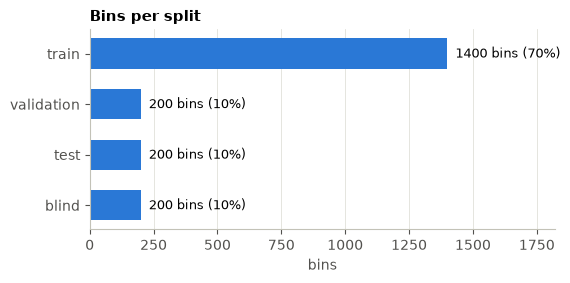

FINDING: 2000 bins split 70% / 10% / 10% / 10% (train / validation / test / blind).


In [3]:
sizes = splits["split"].value_counts().reindex(SPLITS)
fig, ax = plt.subplots(figsize=(6, 2.6))
bars = ax.barh(SPLITS[::-1], sizes[SPLITS[::-1]], color=BLUE, height=0.6)
ax.grid(axis="y", visible=False)
for b, s in zip(bars, SPLITS[::-1]):
    ax.text(b.get_width(), b.get_y() + b.get_height() / 2,
            f"  {int(b.get_width())} bins ({b.get_width() / len(splits):.0%})", va="center", fontsize=9)
ax.set_xlim(0, sizes.max() * 1.3)
ax.set_title("Bins per split")
ax.set_xlabel("bins")
plt.show()
finding(f"{len(splits)} bins split " + " / ".join(f"{sizes[s] / len(splits):.0%}" for s in SPLITS)
        + " (train / validation / test / blind).")

**Check A – every bin in exactly one split, and photos on disk match `splits.csv`.**
**Check B – no exact duplicate photo anywhere** (MD5 fingerprint of every file).
**Check C – no near-duplicate photo across splits.** The same shelf could be photographed twice, giving two
slightly different files. A *difference hash* (16×16 grid of brighter/darker neighbours = 256 bits) is computed
per photo; two photos whose hashes differ in only a few bits look almost the same.

In [4]:
checks = {}

# A. one split per bin, and the files on disk agree with splits.csv
checks["A1 every bin id appears once in splits.csv"] = splits["bin_id"].is_unique
on_disk = {s: {p.stem for p in (DATA / s / "images").glob("*.jpg")} for s in SPLITS}
checks["A2 photos in each folder match splits.csv"] = all(
    on_disk[s] == set(splits.loc[splits["split"] == s, "bin_id"]) for s in SPLITS)
overlap = {(a, b): len(on_disk[a] & on_disk[b]) for i, a in enumerate(SPLITS) for b in SPLITS[i + 1:]}
checks["A3 no bin id in two split folders"] = sum(overlap.values()) == 0

# B. exact duplicates: identical files give identical MD5 fingerprints
photos = pd.DataFrame([{"bin_id": p.stem, "split": s, "path": p}
                       for s in SPLITS for p in sorted((DATA / s / "images").glob("*.jpg"))])
photos["md5"] = [hashlib.md5(p.read_bytes()).hexdigest() for p in photos["path"]]
checks["B  no exact duplicate photos"] = photos["md5"].is_unique

# C. near duplicates: difference hash, then Hamming distance between every pair of photos
def dhash(path, size=16):
    g = np.asarray(Image.open(path).convert("L").resize((size + 1, size)), dtype=np.int16)
    return (g[:, 1:] > g[:, :-1]).ravel()

H = np.stack([dhash(p) for p in photos["path"]]).astype(np.float32)
dist = H @ (1 - H).T + (1 - H) @ H.T                      # number of differing bits, every pair
split_codes = photos["split"].map({s: i for i, s in enumerate(SPLITS)}).to_numpy()
cross = split_codes[:, None] != split_codes[None, :]       # pairs in different splits
iu = np.triu_indices(len(photos), k=1)
cross_d = dist[iu][cross[iu]]
NEAR = 10                                                  # <= 10 of 256 bits = near-identical photo
checks[f"C  no near-duplicate pair across splits (<= {NEAR}/256 bits)"] = int((cross_d <= NEAR).sum()) == 0

for name, ok in checks.items():
    print(("PASS  " if ok else "FAIL  ") + name)
assert all(v for k, v in checks.items() if not k.startswith("C")), "Leakage found: fix the split first."

PASS  A1 every bin id appears once in splits.csv
PASS  A2 photos in each folder match splits.csv
PASS  A3 no bin id in two split folders
PASS  B  no exact duplicate photos
PASS  C  no near-duplicate pair across splits (<= 10/256 bits)


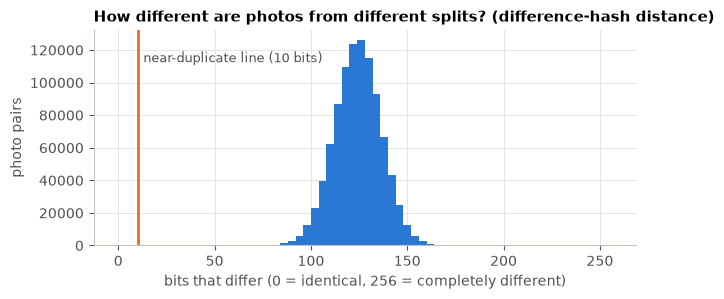

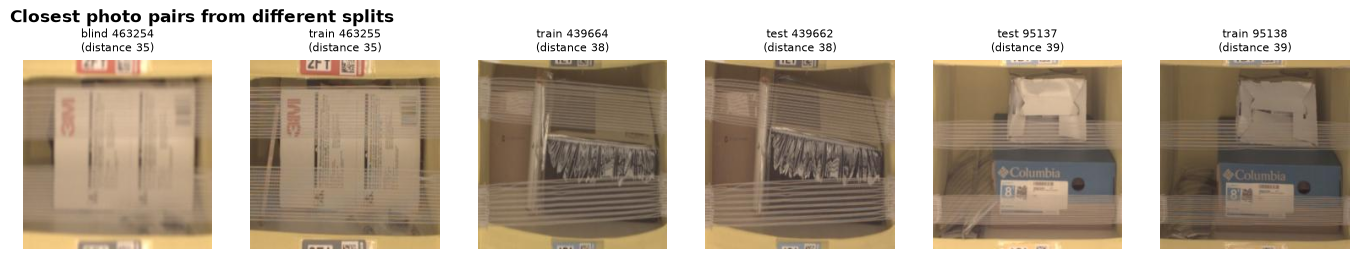

FINDING: No bin, exact duplicate or near-duplicate photo is shared between splits (closest cross-split pair differs in 35 of 256 hash bits).


In [5]:
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(cross_d, bins=np.arange(0, 257, 4), color=BLUE)
ax.axvline(NEAR, color=ORANGE, lw=2)
ax.text(NEAR + 3, ax.get_ylim()[1] * 0.85, f"near-duplicate line ({NEAR} bits)", color="#52514e", fontsize=9)
ax.set_title("How different are photos from different splits? (difference-hash distance)")
ax.set_xlabel("bits that differ (0 = identical, 256 = completely different)")
ax.set_ylabel("photo pairs")
plt.show()

# Show the closest cross-split pairs so the reader can judge by eye
d = np.where(cross, dist, np.inf)
np.fill_diagonal(d, np.inf)
flat = np.argsort(d, axis=None)[: 2 * 3 : 2]               # each pair appears twice (i,j and j,i)
pairs = [np.unravel_index(k, d.shape) for k in flat]
paths, titles = [], []
for i, j in pairs:
    for k in (i, j):
        paths.append(photos.loc[k, "path"])
        titles.append(f"{photos.loc[k, 'split']} {photos.loc[k, 'bin_id']}\n(distance {int(d[i, j])})")
show_grid(paths, titles, ncols=6, title="Closest photo pairs from different splits")
finding(f"No bin, exact duplicate or near-duplicate photo is shared between splits "
        f"(closest cross-split pair differs in {int(cross_d.min())} of 256 hash bits)."
        if all(checks.values()) else "LEAKAGE CHECK FAILED – see the FAIL lines above.")

**Check D – each photo is matched to its own metadata record** (train and validation only; for test only the
file names are compared so its labels stay unseen). The metadata quantities must agree with `labels.csv`.

In [6]:
labels = pd.concat([pd.read_csv(DATA / s / "labels.csv", dtype={"bin_id": str}).assign(split=s)
                    for s in ["train", "validation"]], ignore_index=True)

problems = 0
for _, r in labels.iterrows():
    m = json.loads((DATA / r["split"] / "metadata" / f"{r['bin_id']}.json").read_text())
    items = m.get("BIN_FCSKU_DATA") or {}
    problems += r["image"] != f"{r['bin_id']}.jpg"
    problems += m.get("EXPECTED_QUANTITY") != r["total_units"]
    problems += any(items.get(a, {}).get("quantity", 0) != r[a] for a in CAT)
test_names_ok = ({p.stem for p in (DATA / "test" / "metadata").glob("*.json")} == on_disk["test"])
print(("PASS  " if problems == 0 else f"FAIL ({problems})  ") + "D1 train/validation photo, metadata and labels agree")
print(("PASS  " if test_names_ok else "FAIL  ") + "D2 every test photo has a metadata file with the same bin id")

PASS  D1 train/validation photo, metadata and labels agree
PASS  D2 every test photo has a metadata file with the same bin id


## 3. How often each catalogue product appears

From here on, only **train + validation** are used (1,600 bins), so the test set stays unseen.

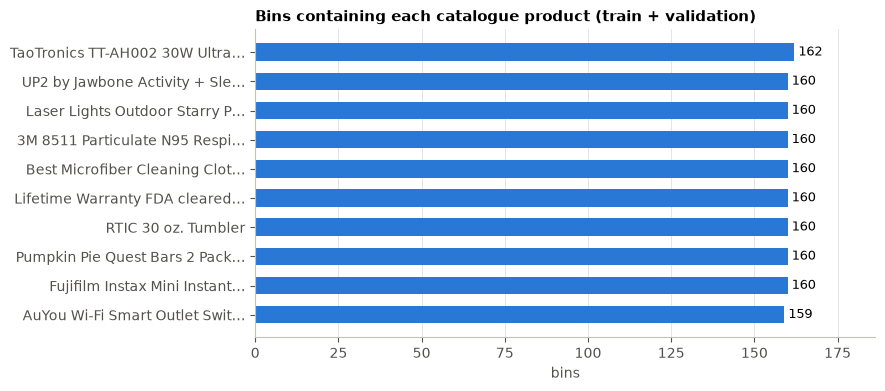

FINDING: Each of the 10 products appears in 159–162 of 1600 train+validation bins: balanced, so no product dominates training.
Bins per product in each split (counts written by prepare_data.py; shows the stratification worked):


,bins_train,bins_validation,bins_test
TaoTronics TT-AH002 30W Ultra…,142,20,20
Fujifilm Instax Mini Instant…,140,20,20
RTIC 30 oz. Tumbler,140,20,20
Pumpkin Pie Quest Bars 2 Pack…,140,20,20
Laser Lights Outdoor Starry P…,140,20,20
Best Microfiber Cleaning Clot…,140,20,20
Lifetime Warranty FDA cleared…,140,20,20
3M 8511 Particulate N95 Respi…,140,20,20
UP2 by Jawbone Activity + Sle…,140,20,20
AuYou Wi-Fi Smart Outlet Swit…,139,20,20


In [7]:
present = (labels[CAT] > 0)
counts = present.sum().sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh([LABEL[a] for a in counts.index], counts.values, color=BLUE, height=0.6)
bar_labels(ax, bars, horizontal=True)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, counts.max() * 1.15)
ax.set_title("Bins containing each catalogue product (train + validation)")
ax.set_xlabel("bins")
plt.show()
balance = "balanced, so no product dominates training" if counts.max() <= 1.25 * counts.min() else "uneven, so some products get far more training examples"
finding(f"Each of the {len(CAT)} products appears in {counts.min()}–{counts.max()} of "
        f"{len(labels)} train+validation bins: {balance}.")

per_split = catalogue.set_index("asin")[["bins_train", "bins_validation", "bins_test"]]
per_split.index = [LABEL[a] for a in per_split.index]
print("Bins per product in each split (counts written by prepare_data.py; shows the stratification worked):")
display(per_split)

## 4. Quantities: how many units per bin, and what the model has to predict

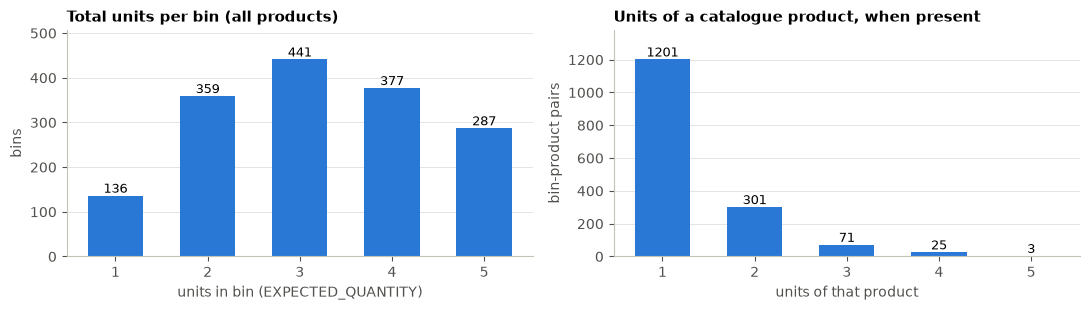

FINDING: The most common bin holds 3 unit(s) (28% of bins); when a catalogue product is present, 75% of the time it is a single unit and only 6% of the time 3 or more.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
tot = labels["total_units"].value_counts().reindex(range(1, 6), fill_value=0)
bars = axes[0].bar(tot.index, tot.values, color=BLUE, width=0.6)
bar_labels(axes[0], bars)
axes[0].set_title("Total units per bin (all products)")
axes[0].set_xlabel("units in bin (EXPECTED_QUANTITY)")
axes[0].set_ylabel("bins")
axes[0].grid(axis="x", visible=False)

q = labels[CAT].to_numpy().ravel()
qp = pd.Series(q[q > 0]).value_counts().reindex(range(1, 6), fill_value=0)
bars = axes[1].bar(qp.index, qp.values, color=BLUE, width=0.6)
bar_labels(axes[1], bars)
axes[1].set_title("Units of a catalogue product, when present")
axes[1].set_xlabel("units of that product")
axes[1].set_ylabel("bin-product pairs")
axes[1].grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
finding(f"The most common bin holds {tot.idxmax()} unit(s) ({tot.max() / len(labels):.0%} of bins); "
        f"when a catalogue product is present, {qp[1] / qp.sum():.0%} of the time it is a single unit "
        f"and only {qp[qp.index >= 3].sum() / qp.sum():.0%} of the time 3 or more.")

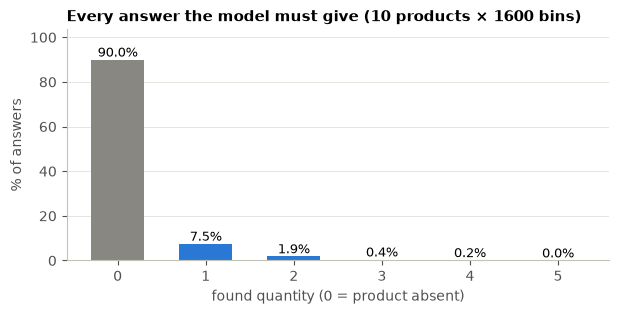

FINDING: 90% of all answers are 0, so a model that always says 'absent' is 90% accurate while finding nothing: accuracy alone is misleading, use precision, recall and F1.


In [9]:
ans = pd.Series(q).value_counts().reindex(range(0, 6), fill_value=0)
fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.bar(ans.index, ans.values / ans.sum() * 100, color=[MUTED] + [BLUE] * 5, width=0.6)
bar_labels(ax, bars, fmt="{:.1f}%")
ax.set_title(f"Every answer the model must give ({len(CAT)} products × {len(labels)} bins)")
ax.set_xlabel("found quantity (0 = product absent)")
ax.set_ylabel("% of answers")
ax.grid(axis="x", visible=False)
plt.show()
finding(f"{ans[0] / ans.sum():.0%} of all answers are 0, so a model that always says 'absent' is "
        f"{ans[0] / ans.sum():.0%} accurate while finding nothing: accuracy alone is misleading, use precision, recall and F1.")

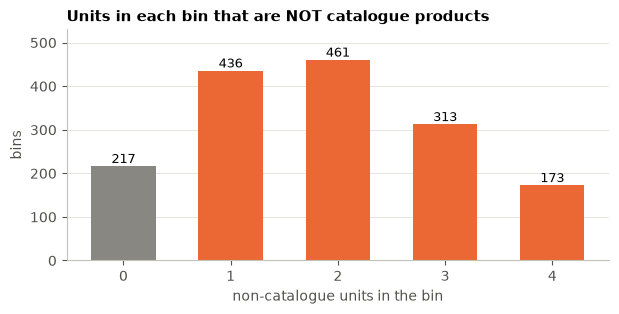

FINDING: 86% of bins also hold products outside the catalogue, which the model must learn to ignore.


In [10]:
other_units = labels["total_units"] - labels[CAT].sum(axis=1)
oc = other_units.value_counts().reindex(range(0, 5), fill_value=0)
fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.bar(oc.index, oc.values, color=[MUTED] + [ORANGE] * 4, width=0.6)
bar_labels(ax, bars)
ax.set_title("Units in each bin that are NOT catalogue products")
ax.set_xlabel("non-catalogue units in the bin")
ax.set_ylabel("bins")
ax.grid(axis="x", visible=False)
plt.show()
finding(f"{(other_units > 0).mean():.0%} of bins also hold products outside the catalogue, "
        f"which the model must learn to ignore.")

## 5. Image quality

Three simple measures per photo (train + validation):
- **brightness** – average grey level (0 black … 255 white)
- **contrast** – spread of grey levels (low = washed out, e.g. tape glare)
- **sharpness** – variance of the Laplacian (an edge detector); low values mean a blurry photo

Photo sizes: {(224, 224): 1600} | colour modes: {'RGB': 1600}


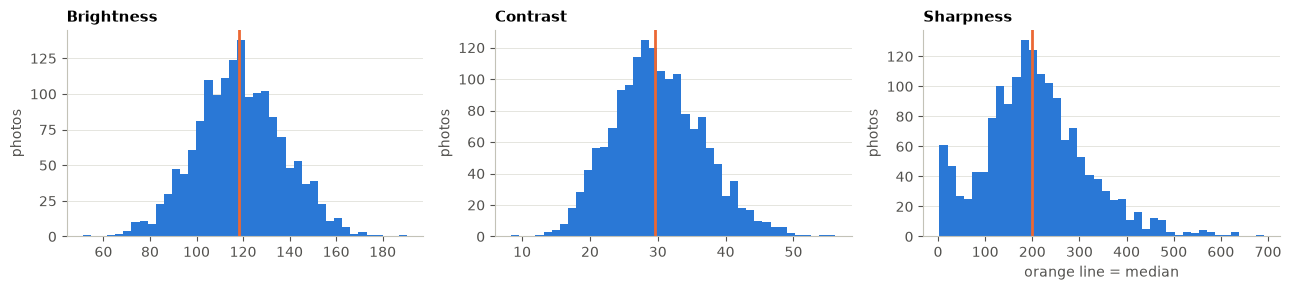

FINDING: All photos are 224×224 RGB; sharpness ranges from 72 (blurriest 10%) to 345 (sharpest 10%), a 4.8× gap, median 200.


In [11]:
def quality(path):
    im = Image.open(path)
    g = np.asarray(im.convert("L"), dtype=np.float32)
    lap = -4 * g[1:-1, 1:-1] + g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:]
    return {"size": im.size, "mode": im.mode, "brightness": g.mean(), "contrast": g.std(), "sharpness": lap.var()}

tv = photos[photos["split"].isin(["train", "validation"])].reset_index(drop=True)
iq = pd.concat([tv, pd.DataFrame([quality(p) for p in tv["path"]])], axis=1)
print("Photo sizes:", iq["size"].value_counts().to_dict(), "| colour modes:", iq["mode"].value_counts().to_dict())

fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, col in zip(axes, ["brightness", "contrast", "sharpness"]):
    ax.hist(iq[col], bins=40, color=BLUE)
    ax.axvline(iq[col].median(), color=ORANGE, lw=2)
    ax.set_title(col.capitalize())
    ax.set_ylabel("photos")
    ax.grid(axis="x", visible=False)
axes[2].set_xlabel("orange line = median")
plt.tight_layout()
plt.show()
p10, p50, p90 = iq["sharpness"].quantile([0.1, 0.5, 0.9])
finding(f"All photos are {iq['size'].iloc[0][0]}×{iq['size'].iloc[0][1]} {iq['mode'].iloc[0]}; sharpness ranges from "
        f"{p10:.0f} (blurriest 10%) to {p90:.0f} (sharpest 10%), a {p90 / max(p10, 1e-6):.1f}× gap, median {p50:.0f}.")

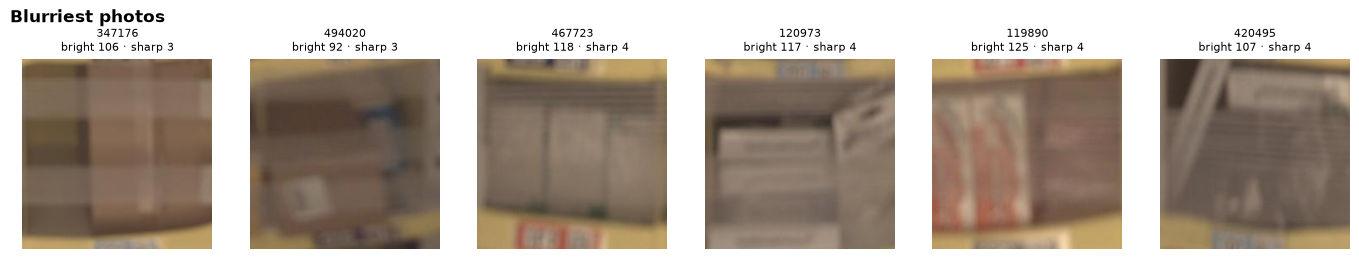

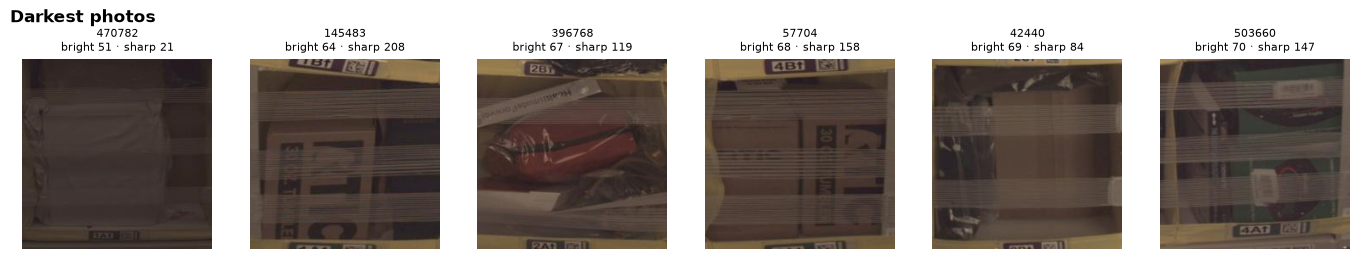

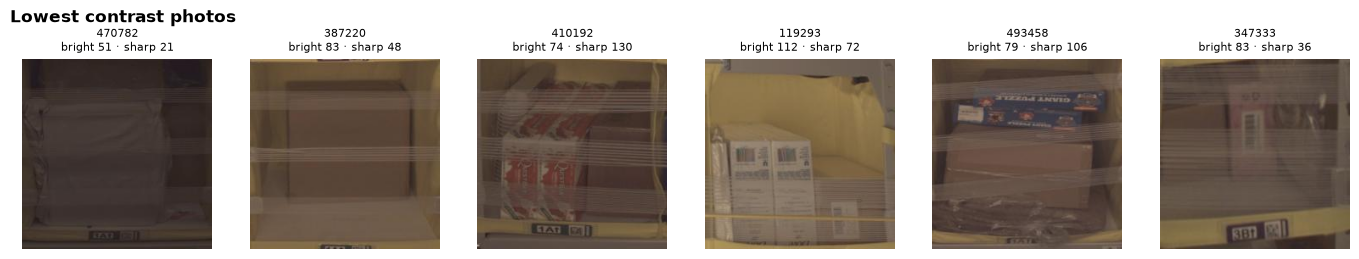

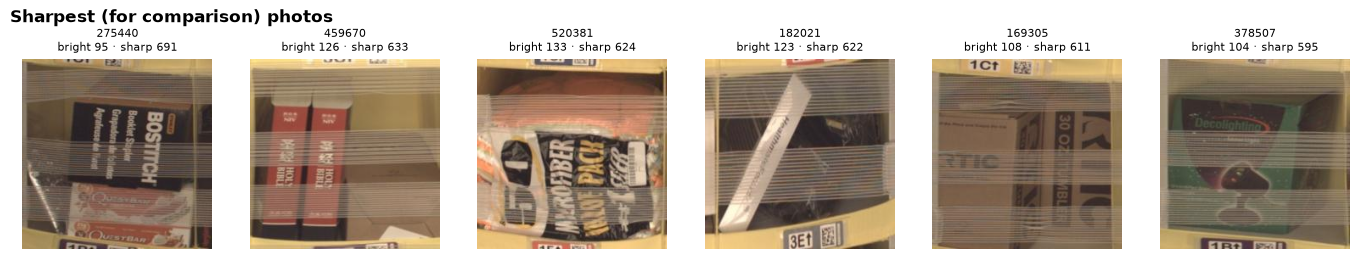

In [12]:
def captions(df):
    return [f"{r.bin_id}\nbright {r.brightness:.0f} · sharp {r.sharpness:.0f}" for r in df.itertuples()]

for col, asc, name in [("sharpness", True, "Blurriest"), ("brightness", True, "Darkest"),
                       ("contrast", True, "Lowest contrast"), ("sharpness", False, "Sharpest (for comparison)")]:
    sel = iq.sort_values(col, ascending=asc).head(6)
    show_grid(list(sel["path"]), captions(sel), title=f"{name} photos")

**What to look for in these grids:** tape strips across the front, glare, items hidden behind other items,
and how small a product can be inside the frame. Add one sentence below with what you see.

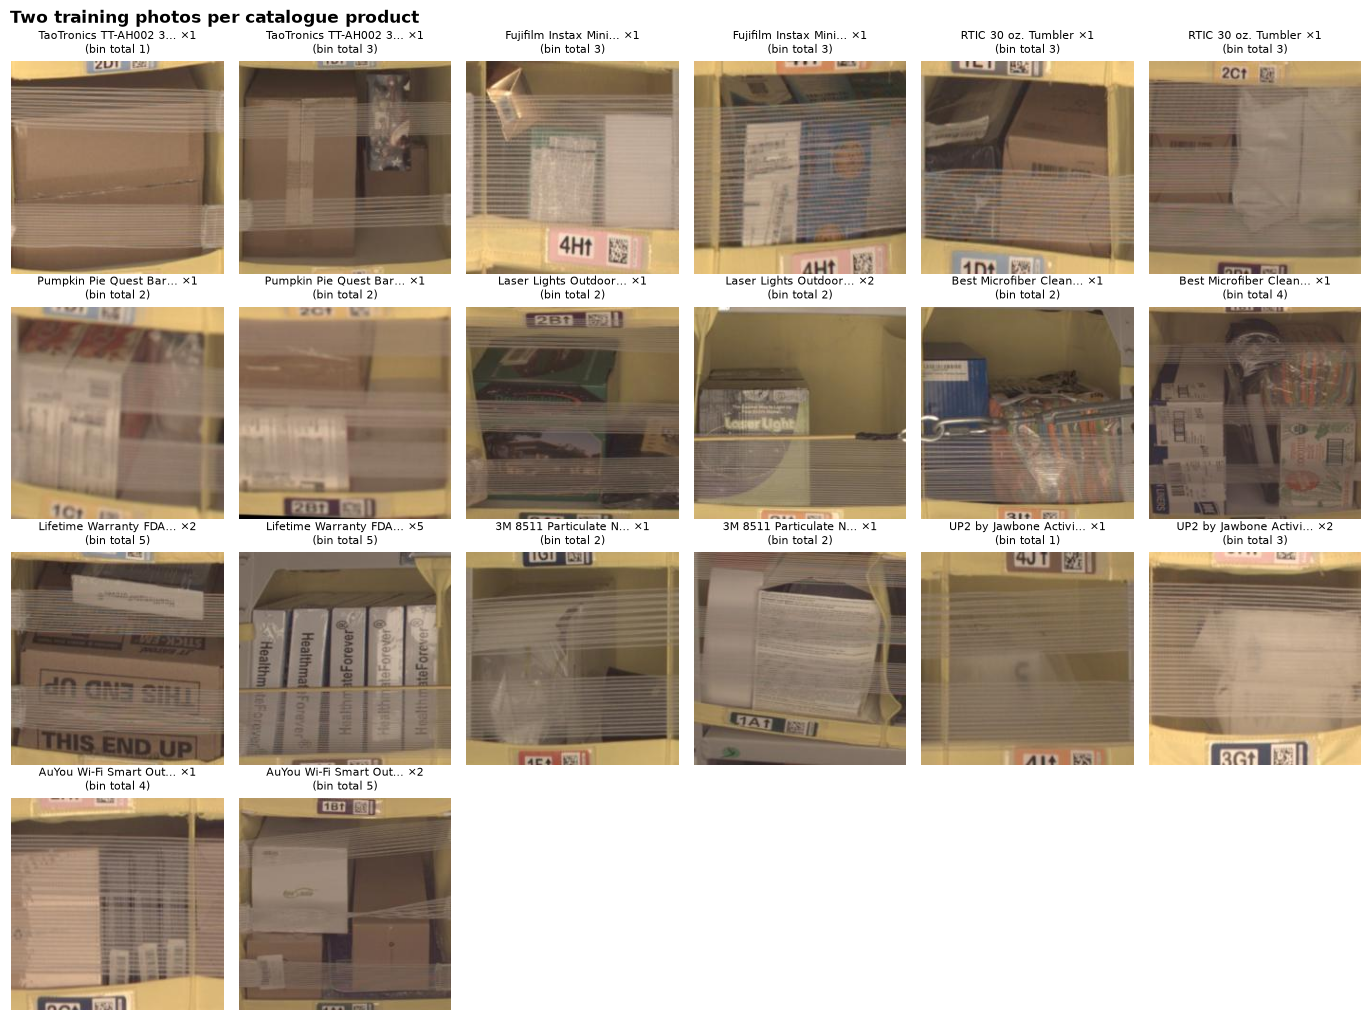

In [13]:
# What the model sees: two random training photos per catalogue product
rng = np.random.default_rng(SEED)
tr = labels[labels["split"] == "train"]
paths, titles = [], []
for a in CAT:
    rows = tr[tr[a] > 0]
    for i in rng.choice(len(rows), size=min(2, len(rows)), replace=False):
        r = rows.iloc[i]
        paths.append(DATA / "train" / "images" / r["image"])
        titles.append(f"{short(LABEL[a], 22)} ×{r[a]}\n(bin total {r['total_units']})")
show_grid(paths, titles, ncols=6, title="Two training photos per catalogue product")

## 6. Odd things in the metadata (train + validation records)

In [14]:
recs = []
for s in ["train", "validation"]:
    for f in sorted((DATA / s / "metadata").glob("*.json")):
        m = json.loads(f.read_text())
        for asin, v in (m.get("BIN_FCSKU_DATA") or {}).items():
            dims = {k: (v.get(k) or {}) for k in ["height", "length", "width", "weight"]}
            recs.append({
                "bin_id": f.stem, "asin": asin, "catalogue": asin in CAT,
                "name": v.get("name"), "normalizedName": v.get("normalizedName"),
                **{k: d.get("value") for k, d in dims.items()},
                "size_unit": dims["height"].get("unit"), "weight_unit": dims["weight"].get("unit"),
                "image_fname": m.get("image_fname"),
            })
meta = pd.DataFrame(recs)

oddities = {
    "records with image_fname filled in (bin id must come from the file name)": int(meta["image_fname"].notna().sum()),
    "records with image_fname missing": int(meta["image_fname"].isna().sum()),
    "product entries where name != normalizedName": int((meta["name"] != meta["normalizedName"]).sum()),
    "product entries with a missing or zero size/weight": int((meta[["height", "length", "width", "weight"]].fillna(0) == 0).any(axis=1).sum()),
    "size units seen": sorted(meta["size_unit"].dropna().unique().tolist()),
    "weight units seen": sorted(meta["weight_unit"].dropna().unique().tolist()),
}
display(pd.Series(oddities, name="count / value").to_frame())

,count / value
records with image_fname filled in (bin id must come from the file name),0
records with image_fname missing,3957
product entries where name != normalizedName,691
product entries with a missing or zero size/weight,39
size units seen,[IN]
weight units seen,[pounds]


,bins,names,sizes,weights
3M 8511 Particulate N95 Respi…,160,1,1,1
Fujifilm Instax Mini Instant…,160,1,2,1
Lifetime Warranty FDA cleared…,160,1,1,1
TaoTronics TT-AH002 30W Ultra…,162,1,2,2
Pumpkin Pie Quest Bars 2 Pack…,160,1,1,1
UP2 by Jawbone Activity + Sle…,160,1,1,1
RTIC 30 oz. Tumbler,160,1,2,2
Laser Lights Outdoor Starry P…,160,1,1,1
Best Microfiber Cleaning Clot…,160,1,1,1
AuYou Wi-Fi Smart Outlet Swit…,159,5,1,1


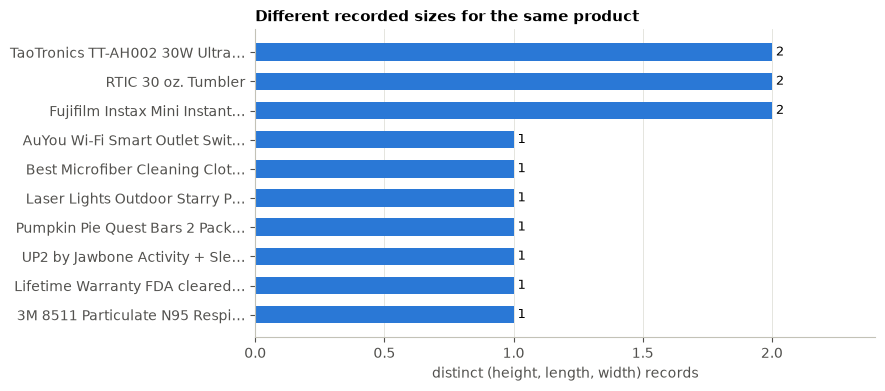

FINDING: 3 of 10 catalogue products have more than one recorded size across bins, so catalogue.csv keeps one record per product and size data should be treated as approximate.


In [15]:
cm = meta[meta["catalogue"]].copy()
cm["size"] = list(zip(cm["height"].round(2), cm["length"].round(2), cm["width"].round(2)))
cons = cm.groupby("asin").agg(bins=("bin_id", "nunique"), names=("name", "nunique"),
                              sizes=("size", "nunique"), weights=("weight", lambda w: w.round(3).nunique()))
cons.index = [LABEL[a] for a in cons.index]
display(cons)

fig, ax = plt.subplots(figsize=(8, 4))
c = cons["sizes"].sort_values()
bars = ax.barh(c.index, c.values, color=BLUE, height=0.6)
bar_labels(ax, bars, horizontal=True)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, max(c.max() * 1.2, 2))
ax.set_title("Different recorded sizes for the same product")
ax.set_xlabel("distinct (height, length, width) records")
plt.show()
n_bad = int((cons["sizes"] > 1).sum())
finding(f"{n_bad} of {len(CAT)} catalogue products have more than one recorded size across bins, "
        "so catalogue.csv keeps one record per product and size data should be treated as approximate."
        if n_bad else "Every catalogue product has one consistent size and weight across its bins.")

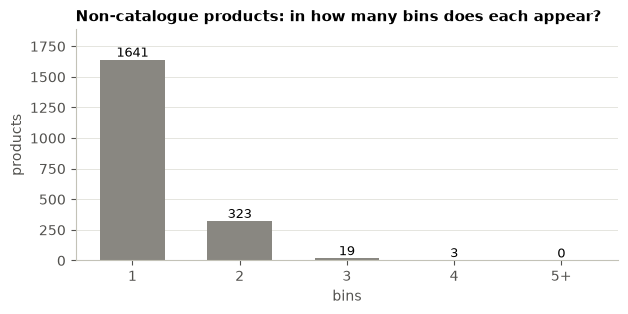

FINDING: Train+validation bins also contain 1986 different non-catalogue products and 83% of them appear in a single bin – far too rare to learn, which is why the catalogue is small.


In [16]:
others = meta[~meta["catalogue"]]
seen = others.groupby("asin")["bin_id"].nunique()
sc = seen.clip(upper=5).value_counts().reindex(range(1, 6), fill_value=0)
fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.bar(["1", "2", "3", "4", "5+"], sc.values, color=MUTED, width=0.6)
bar_labels(ax, bars)
ax.set_title("Non-catalogue products: in how many bins does each appear?")
ax.set_xlabel("bins")
ax.set_ylabel("products")
ax.grid(axis="x", visible=False)
plt.show()
finding(f"Train+validation bins also contain {len(seen)} different non-catalogue products and "
        f"{(seen == 1).mean():.0%} of them appear in a single bin – far too rare to learn, which is why the catalogue is small.")

## 7. Summary of findings

In [17]:
for i, f in enumerate(FINDINGS, 1):
    print(f"{i}. {f}")

1. 2000 bins split 70% / 10% / 10% / 10% (train / validation / test / blind).
2. No bin, exact duplicate or near-duplicate photo is shared between splits (closest cross-split pair differs in 35 of 256 hash bits).
3. Each of the 10 products appears in 159–162 of 1600 train+validation bins: balanced, so no product dominates training.
4. The most common bin holds 3 unit(s) (28% of bins); when a catalogue product is present, 75% of the time it is a single unit and only 6% of the time 3 or more.
5. 90% of all answers are 0, so a model that always says 'absent' is 90% accurate while finding nothing: accuracy alone is misleading, use precision, recall and F1.
6. 86% of bins also hold products outside the catalogue, which the model must learn to ignore.
7. All photos are 224×224 RGB; sharpness ranges from 72 (blurriest 10%) to 345 (sharpest 10%), a 4.8× gap, median 200.
8. 3 of 10 catalogue products have more than one recorded size across bins, so catalogue.csv keeps one record per product and

### What this means for the model (M2) and evaluation (M3)
- **Imbalance:** most answers are 0, so report precision, recall and F1 per product, not plain accuracy, and
  compare against a baseline that always predicts the most common answer.
- **Counting is mostly 0 vs 1:** few bins hold 3+ units of one product, so high counts will be rare and hard.
- **Distractors and photo quality** (other products, tape, blur, hidden items) and **noisy labels** set a
  ceiling on accuracy; expect a modest model.
- **No leakage:** bins, exact duplicates and near-duplicates are not shared between splits, and the test set
  has not been looked at.